# El factor de roca: de dónde sale el único número libre de la ecuación clásica

**Nivel 2: El método en la práctica** · Requiere: 02-classical-prediction/01-the-classical-equation-on-one-blast · Tiempo de lectura: unos 25 minutos

## Objetivos

Los dos artículos de origen dicen que el factor de roca `A` "se estimó para cada tiro", y ninguno imprime un valor. Sin él la ecuación clásica no puede correr. Este cuaderno muestra las dos maneras en que el motor puede obtener uno: desde una tabla de clasificación publicada, e invirtiendo la ecuación sobre una predicción publicada. Luego pregunta cuál sobrevive al contacto con los datos.

Al terminar habrá:

- recuperado el factor de roca de cada sitio invirtiendo la ecuación sobre las predicciones publicadas, y reproducido la tabla fijada del motor;
- medido cuánto varía el factor recuperado dentro de un sitio (lo que prueba la geometría) y entre sitios (que es la roca);
- ejecutado los tres esquemas de clasificación publicados para la roca de Akdaglar y comparado con el valor recuperado.

## Preparación

Instale los paquetes con los pines exactos de `notebooks/requirements.txt`. El motor es `blastfrag`, publicado en PyPI; los otros paquetes son su base numérica y la biblioteca de gráficos.

```bash
pip install blastfrag==0.4.0 numpy==2.5.3 matplotlib==3.11.2
```

Esta celda aún no importa nada del cuaderno: lee las versiones instaladas desde los metadatos de los paquetes y las imprime, de modo que la salida registra qué motor produjo cada número que sigue.

In [1]:
# Imprima la versión instalada de cada paquete que usa este cuaderno
from importlib.metadata import version

for name in ("blastfrag", "numpy", "matplotlib",):
    print(f"{name}=={version(name)}")

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Datos

| Fuente | Titular y URL | Clase de licencia | Archivo que lee el cuaderno |
|---|---|---|---|
| Los tiros de hold-out con la columna clásica que imprime cada artículo | Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957; Kulatilake, Hudaverdi y Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 | hechos numéricos reutilizados con cita; los artículos nunca se distribuyen | `bf.load_holdout()` dentro del paquete `blastfrag` |
| La descripción de la roca de cada sitio (resistencia, densidad, módulo) | los mismos artículos, tal como los lleva el benchmark versionado | hechos numéricos reutilizados con cita | `data/derived/benchmark.json`, campo `site_meta` |
| Las tablas de clasificación | Hudaverdi et al. 2010 Ecs. 2 y 3; Babaeian et al. 2019, https://doi.org/10.1016/j.jrmge.2018.11.006 (Tablas 1 y 2) | las tablas se reproducen con cita | `bf.rock_factor` y `bf.SCHEMES` en el motor |

## Método

**Ruta 1, una tabla de clasificación.** El índice de tronabilidad de Lilly es la suma de cinco clasificaciones (descripción del macizo, espaciamiento de diaclasas, orientación del plano de diaclasas, un término de densidad y un término de resistencia), y el factor de roca es 0,06 veces el índice (Hudaverdi et al. 2010, https://doi.org/10.1002/nag.957, Ecs. 2 y 3). Babaeian et al. 2019 (https://doi.org/10.1016/j.jrmge.2018.11.006) imprimen la misma suma con otro término de resistencia y otras tablas de clasificación, y tabulan un tercero, una búsqueda por cinco bandas de Hustrulid.

**Ruta 2, inversión.** La ecuación del cuaderno anterior es lineal en `A`, así que una predicción publicada `x50_pub` de un tiro con `V` y `Q` conocidos lo fija:

```
A = x50_pub / [ (V / Q)^0.8 * Q^(1/6) * (RWS / 115)^(-19/30) ]
```

El valor recuperado solo merece confianza si es casi el mismo para todos los tiros de un sitio, porque la roca no cambia dentro de una campaña. Esa constancia es también una prueba de la reconstrucción de la geometría: un error en el bordo o en la altura de banco dispersaría el factor.

### Paso 1: la columna publicada

El motor incluye los dos conjuntos de hold-out con, para cada tiro, la predicción clásica que imprimió cada artículo. La celda lista esas columnas y cuántos tiros de cada una tienen geometría resoluble (la inversión necesita `V` y `Q`).

In [2]:
# Importaciones, y luego la unión de los dos hold-outs publicados y las columnas de predicción que lleva cada tiro
import json
import re
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np

DERIVED = Path("../../../data/derived")
holdout = bf.load_holdout(protocol="union")
print("tiros en la unión de los hold-outs:", len(holdout))
print("columnas publicadas del primer tiro:", sorted(holdout[0].meta["published"]))
with_geometry = [b for b in holdout if bf.has_absolute_geometry(b)]
for column in ("kuzram_2010", "kuzram_2012"):
    n = sum(1 for b in with_geometry if b.meta["published"].get(column) is not None)
    print(f"{column}: {n} tiros con valor impreso y geometría resoluble")

tiros en la unión de los hold-outs: 14
columnas publicadas del primer tiro: ['kuzram_2010', 'kuzram_2012', 'nn_mean_2012', 'regression_2010', 'regression_2012']
kuzram_2010: 12 tiros con valor impreso y geometría resoluble
kuzram_2012: 12 tiros con valor impreso y geometría resoluble


### Paso 2: invertir la ecuación en cada tiro

Para cada tiro de hold-out la celda reconstruye el patrón, toma `V` y `Q` y llama a `back_solve_rock_factor` con la predicción impresa de 2012. Luego agrupa los valores recuperados por sitio e informa la media y la dispersión relativa (máximo menos mínimo sobre la media).

In [3]:
# Recuperar el factor de roca de cada tiro de hold-out desde su predicción publicada de 2012
per_site = {}
for blast in with_geometry:
    published = blast.meta["published"].get("kuzram_2012")
    if published is None:
        continue
    pattern = bf.reconstruct_pattern(blast)
    factor = bf.back_solve_rock_factor(published, rock_volume_m3=pattern.rock_volume_m3, charge_mass_kg=pattern.charge_mass_kg)
    per_site.setdefault(blast.site, []).append(factor)

print(f"{'sitio':<14}{'n':>3}{'A medio':>10}{'dispersión':>12}   fijado en el motor")
for site, values in sorted(per_site.items()):
    mean = sum(values) / len(values)
    spread = (max(values) - min(values)) / mean
    print(f"{site:<14}{len(values):>3}{mean:>10.2f}{spread:>11.1%}   {bf.SITE_ROCK_FACTOR[site]}")
agree = all(round(sum(v) / len(v), 2) == bf.SITE_ROCK_FACTOR[s] for s, v in per_site.items())
print("la tabla recalculada iguala la fijada a dos decimales:", agree)

sitio           n   A medio  dispersión   fijado en el motor
Akdaglar        2      6.72       3.7%   6.72
Dongri-Buzurg   1      3.68       0.0%   3.68
Enusa           1     10.97       0.0%   10.97
Mrica           1      6.32       0.0%   6.32
Murgul          2      9.23       1.5%   9.23
Ozmert          2      6.44       1.6%   6.44
Reocin          1     12.14       0.0%   12.14
Reocin-UG       1     11.19       0.0%   11.19
Soma            1      6.24       0.0%   6.24
la tabla recalculada iguala la fijada a dos decimales: True


### Paso 3: las dos columnas impresas discrepan

El artículo de 2010 imprimió predicciones clásicas mayores que el de 2012 para los mismos tiros. Invertir cada columna da un factor distinto por sitio. `derive_site_rock_factors` recibe la columna como argumento; la celda pone ambos resultados lado a lado. Mezclar columnas sería un defecto, así que el motor fija una.

In [4]:
# El factor recuperado desde la columna de cada artículo, y la razón entre ambos
f2012 = bf.derive_site_rock_factors("kuzram_2012")
f2010 = bf.derive_site_rock_factors("kuzram_2010")
print(f"{'sitio':<14}{'A 2012':>8}{'A 2010':>8}{'2010/2012':>11}")
ratios = []
for site in sorted(f2010):
    ratio = f2010[site][0] / f2012[site][0]
    ratios.append(ratio)
    print(f"{site:<14}{f2012[site][0]:>8.2f}{f2010[site][0]:>8.2f}{ratio:>11.3f}")
print(f"razón media = {sum(ratios) / len(ratios):.3f}")

sitio           A 2012  A 2010  2010/2012
Akdaglar          6.72    7.03      1.045
Dongri-Buzurg     3.68    4.14      1.125
Enusa            10.97   11.97      1.091
Mrica             6.32    7.11      1.125
Murgul            9.23   10.05      1.088
Ozmert            6.44    7.04      1.094
Reocin-UG        11.19   12.22      1.092
Soma              6.24    6.78      1.086
razón media = 1.093


### Paso 4: qué da una tabla de clasificación para la misma roca

La descripción de la roca de Akdaglar (una arenisca, con su resistencia, densidad y módulo) se lee del benchmark versionado, y el tamaño de bloque in situ del corpus. Los esquemas de clasificación necesitan además una descripción del macizo y una orientación del plano de diaclasas que este corpus no trae, así que la celda prueba cada categoría que reconocen las tablas e informa el factor menor y mayor que puede producir cada esquema. El espaciamiento de diaclasas se toma como el tamaño medio de bloque in situ del sitio, un supuesto de este cuaderno y no un dato.

In [5]:
# Leer la descripción de roca de Akdaglar del benchmark versionado y correr cada esquema sobre las categorías que reconoce
benchmark = json.loads((DERIVED / "benchmark.json").read_text(encoding="utf-8"))
text = benchmark["site_meta"]["Akdaglar"]["rock"]
ucs = float(re.search(r"UCS ([\d.]+) MPa", text)[1])
density = float(re.search(r"density ([\d.]+) g/cm3", text)[1])
modulus = float(re.search(r"E ([\d.]+) GPa", text)[1])
blocks = [b.XB_m for b in bf.load_training_corpus() if b.site == "Akdaglar"]
block = sum(blocks) / len(blocks)
print("descripción de la roca:", text, "| bloque in situ medio =", round(block, 3), "m")

ranges = {}
for scheme in bf.SCHEMES:
    values = []
    for mass in ("powdery", "blocky", "vertically_jointed", "massive"):
        for orientation in ("horizontal", "dip_out_of_face", "strike_normal_to_face", "dip_into_face"):
            rock = bf.Rock(E_GPa=modulus, in_situ_block_m=block, ucs_mpa=ucs, density_t_m3=density, rock_mass_description=mass,
                           joint_spacing_m=block, joint_plane_orientation=orientation)
            try:
                values.append(bf.rock_factor(rock, scheme=scheme))
            except Exception:
                continue  # a category this scheme does not recognise
    ranges[scheme] = (min(values), max(values), len(values))
recovered = bf.SITE_ROCK_FACTOR["Akdaglar"]
print(f"{'esquema':<18}{'menor':>8}{'mayor':>9}{'categorías':>14}")
for scheme, (low, high, n) in ranges.items():
    print(f"{scheme:<18}{low:>8.2f}{high:>9.2f}{n:>14}")
print("recuperado por inversión, Akdaglar:", recovered)

descripción de la roca: sandstone, density 2.70 g/cm3, UCS 81 MPa, E 16.9 GPa | bloque in situ medio = 1.185 m
esquema              menor    mayor    categorías
lilly-hudaverdi       2.75     4.85            12
lilly-babaeian        3.44     5.54            12
hustrulid             7.00     7.00            16
recuperado por inversión, Akdaglar: 6.72


La última celda dibuja el factor recuperado de cada sitio junto al rango que permiten las tablas de clasificación para el único sitio cuya roca está descrita (Akdaglar).

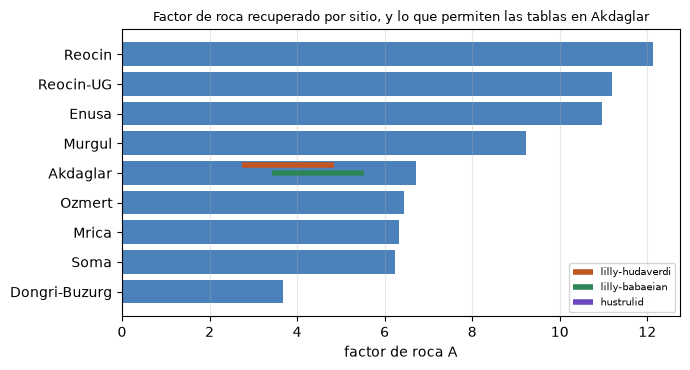

In [6]:
# Factor recuperado por sitio, con los rangos de las tablas de clasificación para Akdaglar
order = sorted(bf.SITE_ROCK_FACTOR, key=bf.SITE_ROCK_FACTOR.get)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(order, [bf.SITE_ROCK_FACTOR[s] for s in order], color="#2b6cb0", alpha=0.85)
row = order.index("Akdaglar")
colors = {"lilly-hudaverdi": "#c05621", "lilly-babaeian": "#2f855a", "hustrulid": "#6b46c1"}
for k, (scheme, (low, high, _)) in enumerate(ranges.items()):
    ax.plot([low, high], [row + 0.25 - 0.25 * k] * 2, color=colors[scheme], lw=4, solid_capstyle="butt", label=scheme)
ax.set_xlabel("factor de roca A")
ax.set_title("Factor de roca recuperado por sitio, y lo que permiten las tablas en Akdaglar")
ax.title.set_fontsize(9)
ax.legend(fontsize=7, loc="lower right")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
plt.show()

## Resultados

**La inversión reproduce la tabla del motor.** Recalcular el factor desde las predicciones impresas de 2012 da el valor fijado de cada sitio a dos decimales. Dentro de un sitio el factor recuperado casi no se mueve (una dispersión de unos pocos por ciento como máximo, y cero en los sitios con un solo tiro utilizable), que es lo que produce redondear las predicciones impresas a dos decimales. Entre sitios va de menos de 4 a más de 12, de modo que la roca, no la aritmética, lleva la variación.

**Los dos artículos discrepan, y la discrepancia es un resultado.** La columna de 2010 implica factores cerca de 9 por ciento mayores que la de 2012. Son números publicados distintos para los mismos tiros, así que el motor fija la columna de 2012, la tabla que lleva los tres brazos publicados, y nunca mezcla las dos.

**Las tablas de clasificación no fijan el factor.** Para el único sitio cuya roca describe el corpus, los esquemas de Lilly cubren una banda ancha (según dos categorías que este corpus no registra) y ninguno alcanza el valor recuperado; la búsqueda de Hustrulid devuelve un único valor cercano a él. Las tablas discrepan entre sí tanto como discrepan de los datos. Por eso el producto distribuye los factores recuperados, y dice en cada predicción que son derivados.

**Qué no muestra esto.** Los factores recuperados se derivan de las predicciones publicadas de los mismos tiros que contienen los hold-outs, así que el brazo clásico que los usa lleva conocimiento del sitio en que se puntúa. Los cuadernos siguientes miden cuánto del puntaje clásico se toma prestado así.

## Resumen

- La ecuación clásica es lineal en el factor de roca, así que una predicción publicada lo fija; invertir la columna de 2012 reproduce los nueve factores fijados del motor.
- El factor recuperado es casi constante dentro de un sitio, lo que valida la geometría, y abarca un rango de tres veces entre sitios.
- Las columnas de 2010 y 2012 implican factores distintos; el motor fija una y nunca las mezcla.
- Las tablas de clasificación no pueden fijar el factor en este corpus: necesitan categorías que el corpus no registra y discrepan entre sí.
- Siguiente: el cuaderno 03 compara los brazos clásicos del motor con las tablas de hold-out publicadas (nivel 3).

## Referencias

- Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 (Ecs. 1 a 3, la columna clásica de 2010)
- Kulatilake, Hudaverdi y Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 (el hold-out de 2012 y su columna clásica)
- Babaeian et al. 2019, https://doi.org/10.1016/j.jrmge.2018.11.006 (Tablas 1 y 2, la segunda tabla de clasificación y la búsqueda de Hustrulid)
- `blastfrag` 0.4.0, el motor, en PyPI: https://pypi.org/project/blastfrag/